In [1]:
source('../../../R/preamble.R')
library(ggh4x)

In [2]:
d = read.tsv('../../../datasets/genomics/04_gene_attribution/results/d_labeled.tsv')
tid_to_mutator_bg = read.tsv('../../../datasets/genomics/06_mutators/results/tid_to_mutator_bg.tsv')
v = read.tsv('../../../datasets/genomics/04_gene_attribution/results/v.tsv')
initial_variants = read.tsv('../../../datasets/genomics/04_gene_attribution/results/initial_variants')

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop, tid, and effect.
ℹ Output is grouped by pop and tid.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, tid, effect))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Warning message in geom_text_repel(data = labels, size = 2.5, hjust = 0, nudge_x = 7.5, :
“Ignoring unknown parameters: `label.padding` and `label.r`”


Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


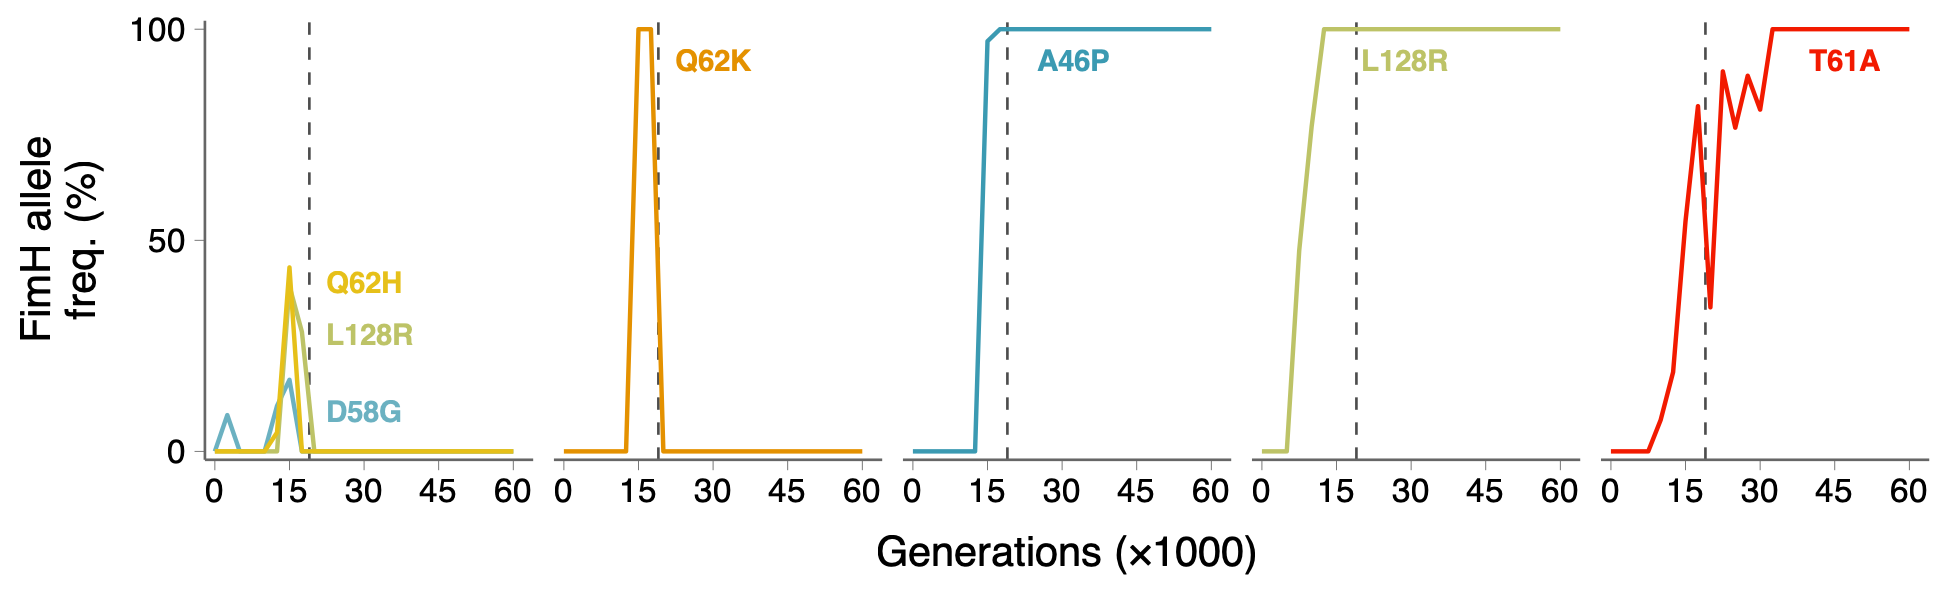

In [3]:
# One-line version for pure pops
size(2,6.5)
lwd = 0.5
pure = c('A','B','C','D','F')

library(ggrepel)

labels = d %>%

    filter(pop %in% pure, context == 'fimH', cat != 'synonymous') %>%
    group_by(pop, tid, effect) %>%
    summarise(
        gen = min(gen[freq == max_f]),
        freq = max_f[1]
    )

d %>% 
    filter(
        context=='fimH', 
        cat!='synonymous',
        pop %in% pure, # cross-contaminants
        #gen*2.5<=45
    ) %>% 

ggplot() + aes(gen*2.5, freq*100, col = effect, group = tid) +

    scale_y_continuous(breaks=100*seq(0,1,0.5), expand=expansion(mult=0.02)) + 
    scale_x_continuous(limits = c(-2, 60+2*2), breaks = seq(0,60,15), expand = c(0,0)) +

    geom_vline(xintercept = 19, lwd=0.3, lty=2, col='grey30') +
    facet_grid(~pop) + 
    
    theme(strip.background = eb, strip.text=eb, panel.grid=eb) +
    geom_line(lwd=lwd) +

    geom_text_repel(#direction = 'y',
        data = labels,
        size = 2.5, hjust = 0, nudge_x = 7.5, nudge_y = -0.075*100, segment.color = 'transparent',
        fontface = 'bold', label.padding = unit(0.5, 'mm'), label.r = unit(0.1, 'mm'),
        aes(label = effect)
    ) +

    labs(x = 'Generations (×1000)', y = 'FimH allele\nfreq. (%)') + nl

psave('Plots/fimH_mutation_traces_pure_pops')

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop, tid, context, and effect.
ℹ Output is grouped by pop, tid, and context.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, tid, context, effect))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.


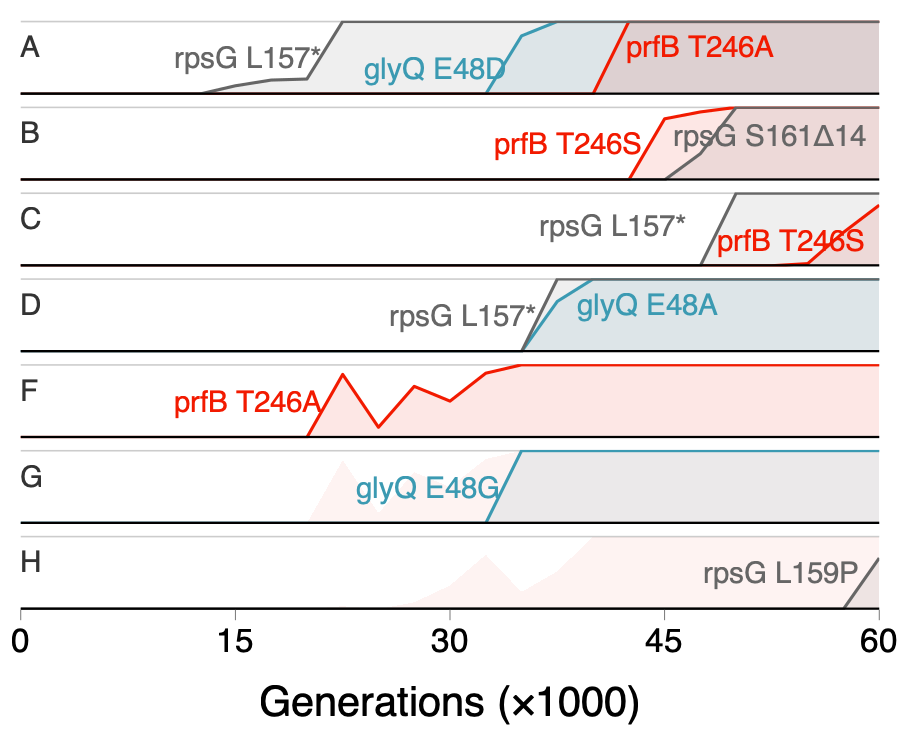

In [4]:
small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

# One-line version for pure pops
size(2.5, 3)

lwd = 0.35

pure = c('A','B','C','D','F')
scars = c("rpsG_1", "rpsG_3", "rpsG_4", "glyQ_2", "glyQ_6", "glyQ_5", "prfB_1", "prfB_3")

discrete_pal = c('#3B9AB2', '#7D3C98', '#EBCC2A', '#95A5A6', '#F21A00', '#27AE60')

library(ggrepel)

labels = d %>%

    filter(vid %in% scars, pop != 'E', pop == origin) %>%
    group_by(pop, tid, context, effect) %>%
    summarise(
        gen = min(gen[freq > 0.3]),
        freq = 0.5 #max_f[1]
    ) %>% 

    # Correct the prfB effects
    mutate(
        effect = case_when(
            context == 'prfB' & effect == 'H246R' ~ 'T246A',
            context == 'prfB' & effect == 'H246L' ~ 'T246S',
            T ~ effect
            )
        )
            

letters = tibble(pop = c('A','B','C','D','F','G','H'), gen=0, freq=0.5, context=NA, tid=NA)

d_scars =
d %>% 
    filter(
        vid %in% scars, pop != 'E'#pop == origin,
    ) 

d_scars %>% 

ggplot() + aes(
        gen*2.5, freq*100, 
        ymin = 0, ymax = freq*100,
        col = context, fill = context, group = tid
    ) +

    scale_y_continuous(breaks=100*c(0,1), expand=expansion(mult=c(0.01,0.01))) + 
    scale_x_continuous(limits = c(0, 60), breaks = seq(0,60,15), expand = c(0,0)) +

    facet_grid(pop~.) + 
    
    theme(
        panel.spacing.y = unit(1,'mm'), # spacing between facets
        strip.background = eb, strip.text = eb,
        panel.grid=eb,
        axis.title.y=eb, axis.text.y=eb, axis.ticks.y=eb, 
        axis.line.y=eb, axis.line.x=eb
    ) +

    # Top lines
    geom_hline(yintercept = 100, lwd=0.2, col='grey80') +

    # Variant lines
    geom_ribbon(
        aes(alpha = pop != origin),
        lwd = lwd, lty = 0
    ) +
    scale_alpha_manual(values = c(0.1, 0.05)) +
    geom_line(
        data = d_scars %>% filter(pop == origin),
        lwd=lwd
    ) +
    # geom_point(
    #     data = d_scars %>% filter(freq!=0, freq!=1),
    #     size = 0.2
    # ) +

    # Bottom lines
    geom_hline(yintercept = 0, lwd=lwd, col=b) +

    # Mutation labels
    geom_text_repel(
        data = labels, 
        #direction = 'x',
        size = 2.5, hjust = 1, nudge_x = -1.5, nudge_y = 0, segment.color = 'transparent',
        #label.padding = unit(0.5, 'mm'), label.r = unit(0.1, 'mm'),
        aes(label = paste(context, effect))
    ) +

    # Pop labels
    geom_text(
        data = letters,
        hjust=0, vjust=0, col='grey20', size=2.5,
        aes(label=pop)
    ) +

    scale_color_manual(values=c(discrete_pal[1], discrete_pal[5], 'grey40')) +
    scale_fill_manual(values=c(discrete_pal[1], discrete_pal[5], 'grey40')) +

    small_titles + small_text + 
    labs(x = 'Generations (×1000)', y = 'Allele freq. (%)') + nl

psave('Plots/domestication_scars')

In [5]:
d_replays = read.tsv('../../../datasets/genomics/04_gene_attribution/results/d_labeled_replays.tsv')

In [6]:
all_letters = c('A','B','C','D','E','F','G','H')

sspA_replays = d_replays %>%
    filter(context == 'sspA', aa_pos > 80) %>% 
    mutate(reactor = substring(pop, 2, 2)) %>% 
    select(reactor, gene_name=context, effect, aa_pos, codon_ref, codon_alt, freq) %>% 
    
    complete(reactor = all_letters, fill=list(freq=0)) %>% 

    mutate(lineage = paste0('A→', reactor))

sspA_replays

reactor,gene_name,effect,aa_pos,codon_ref,codon_alt,freq,lineage
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<chr>
A,sspA,R96C,96,CGC,TGC,0.9835,A→A
B,NA,NA,NA,NA,NA,0.0000,A→B
C,sspA,L101R,101,CTG,CGG,0.7521,A→C
D,sspA,R96S,96,CGC,AGC,1.0000,A→D
E,sspA,R100S,100,CGT,AGT,1.0000,A→E
F,NA,NA,NA,NA,NA,0.0000,A→F
G,sspA,R100S,100,CGT,AGT,1.0000,A→G
H,NA,NA,NA,NA,NA,0.0000,A→H


In [7]:
small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

discrete_pal = c('#3B9AB2', '#7D3C98', '#EBCC2A', '#95A5A6', '#F21A00', '#27AE60')

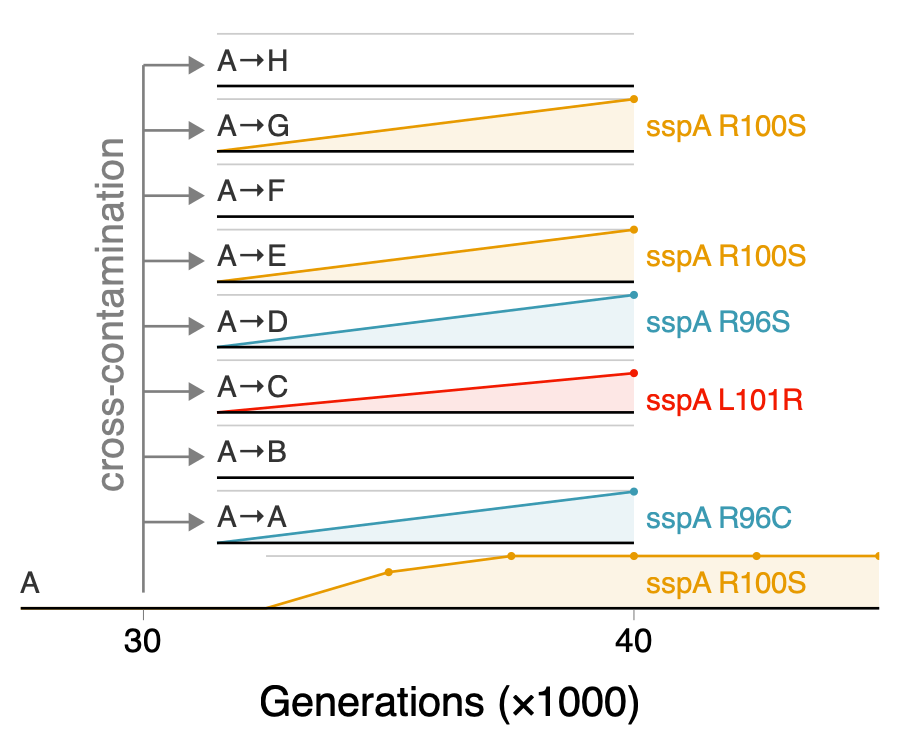

In [8]:
lwd = 0.3
grey = 'grey50'
pad = 0.25

size(2.5, 3)

sspA_in_main = d %>% 
    filter(
        context == 'sspA', pop == 'A', gen >= 11, gen <= 18
    ) %>% 
    mutate(aa_pos = as.integer(aa_pos), gen = gen*2.5) %>% 
    select(reactor=pop, gen, gene_name=context, effect, aa_pos, codon_ref, codon_alt, freq, lineage=pop)

sspA_in_contams =
bind_rows(
    sspA_replays %>% mutate(gen=31.5, freq=0),
    #sspA_replays %>% filter(freq>0.98) %>% mutate(gen=39),
    sspA_replays %>% mutate(gen=40)
    )

sspA_for_plotting =
bind_rows(sspA_in_contams, sspA_in_main) %>% 
    mutate(
        elevation = as.numeric(fct_reorder(lineage, lineage!='A')) - 1,
        ymin = elevation*(1+pad),
        ymax = ymin+freq
        )

letters = sspA_for_plotting %>%
    group_by(lineage) %>%
    filter(gen == min(gen))

mutations = sspA_for_plotting %>%
    filter(gen == 40, !is.na(aa_pos))

sspA_for_plotting %>% filter(!is.na(aa_pos)) %>% 

ggplot() + aes(
        gen, y=ymax, ymin=ymin, ymax=ymax, group=lineage,
        col=aa_pos, fill=aa_pos
    ) +

    scale_x_continuous(limits = c(27.5, 45), breaks = c(30, 40), expand = c(0,0)) +
    ycont(-0.03, 9*(1+pad)) +

    theme(
        panel.grid=eb,
        axis.title.y=eb, axis.text.y=eb, axis.ticks.y=eb, 
        axis.line.y=eb, axis.line.x=eb
    ) + nl +
    
    # Top line
    geom_line(
        data = filter(sspA_for_plotting, !(lineage == 'A' & gen <= 31)), aes(y=ymin+1), 
        lwd=0.2, col='grey80'
    ) +

    # Variant lines
    geom_ribbon(lwd = lwd, alpha = 0.1, lty = 0) +
    geom_line(lwd=lwd) +
    geom_point(
        data = filter(sspA_for_plotting, gen!=31.5, freq>0), size = 0.25
    ) +

    # Bottom line
    geom_line(
        data = sspA_for_plotting, aes(y=ymin), lwd=lwd, col=b
    ) +

    # Lineage labels
    geom_text(
        data = letters,
        aes(label=lineage, y=ymin+0.5),
        hjust=0, vjust=0.5, col='grey20', size=2.5,
    ) +

    # Mutation labels
    geom_text(
        data = mutations, nudge_y = -0.5, x = 40.25,
        size = 2.5, hjust = 0, vjust=0.5,
        aes(label = paste(gene_name, effect))
    ) +

    # Arrows
    annotate(
        geom = 'segment', x = 30, xend = 30, y = 0.3, yend = 8*(1+pad)+0.4,
        lwd = lwd, col = grey
    ) +
    add_arrows(
        x = 30, y = (1:8)*(1+pad) + 0.4,
        xend = 31.2, yend = (1:8)*(1+pad) + 0.4,
        lwd = lwd, col = grey
    ) +
    add_text(
        29.6, 4.5*(1+pad),
        'cross-contamination', angle=90, hjust=0.5, vjust=0, size=3.3, col = grey
    ) +

    small_text + small_titles + xlab('Generations (×1000)')

psave('Plots/A_takeover_sspA')

# FhuA and mutators

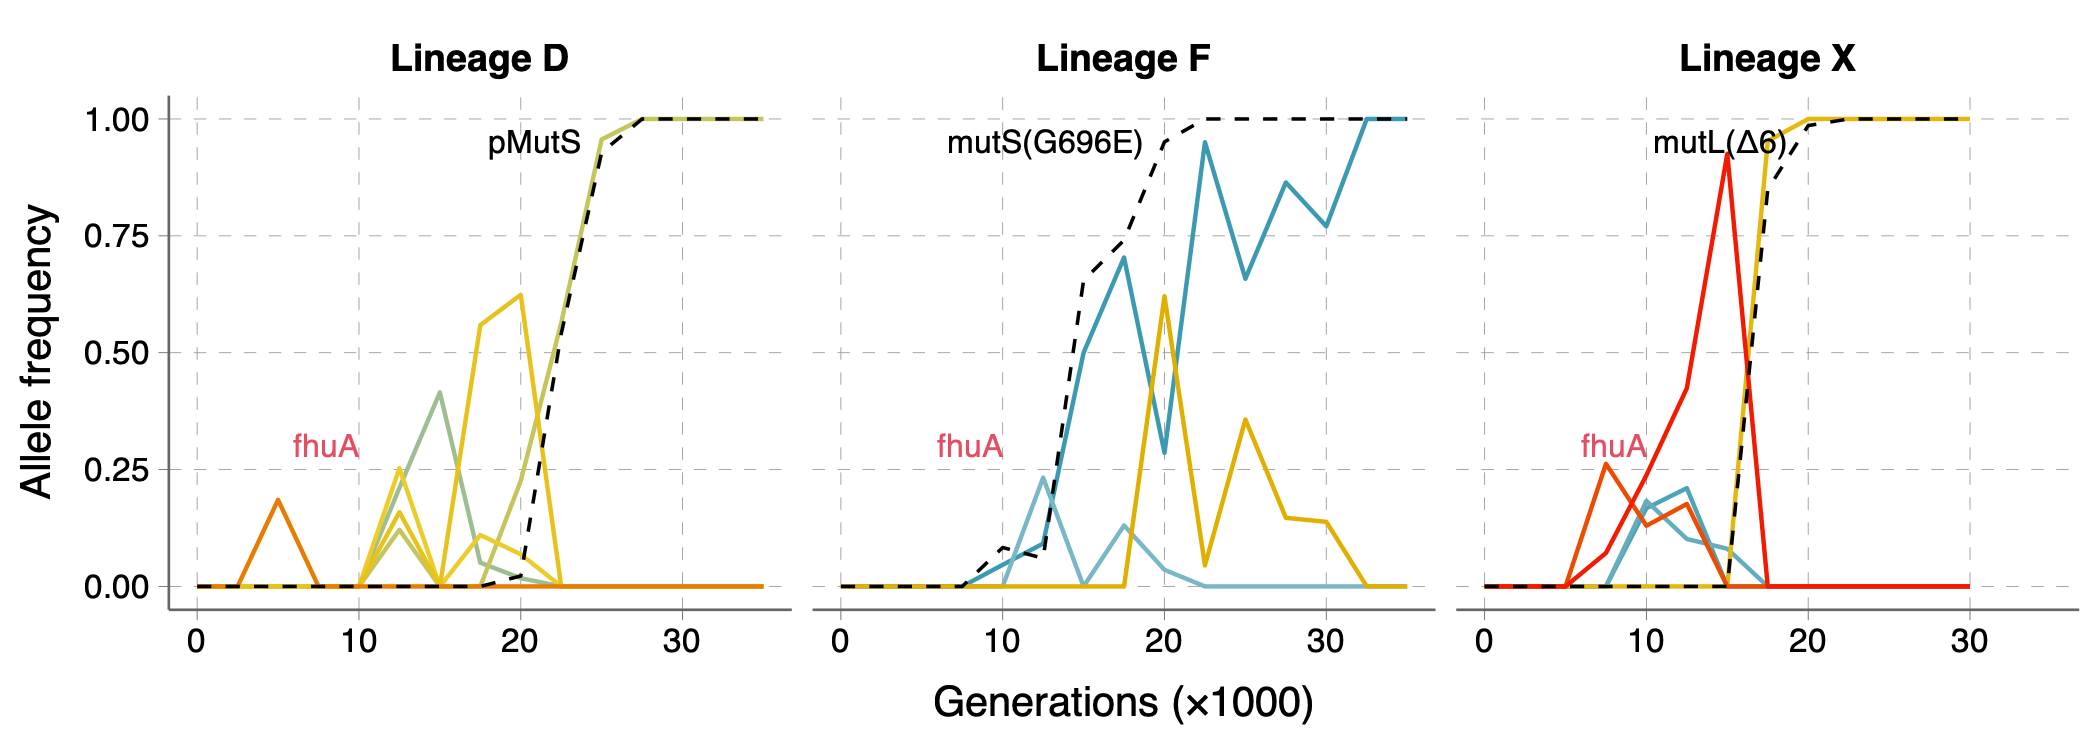

In [9]:
size(2.5,7)

mutators = c('mutS_1', 'mutL_1', 'ygbA/mutS_1')
reversions = c('mutS_2')

mutator_labels = c('mutS_1'='mutS(G696E)', 'mutL_1'='mutL(Δ6)', 'ygbA/mutS_1'='pMutS')
lwd = 0.4

sub = d %>% filter(pop %in% c('X','D','F'), gen <=14)

sub %>%
    filter(context=='fhuA') %>% 

ggplot() + aes(gen*2.5, freq, col=paste(vid), group=tid) + 

    #scale_color_viridis_d(option='magma', begin=0.5, end=0.9) + 
    nl +

    # fhuA
    geom_line(lwd=0.5) +
    add_text(8, 0.3, 'fhuA', size=2.7, col = '#E34E65FF') +

    # Mutators
    geom_line(
        data = sub %>% filter(vid %in% mutators),
        lwd=lwd, col=b, lty=2
    ) +
    geom_text(
        data = sub %>% filter(vid %in% mutators, gen==fixation),
        size=2.7, nudge_y=-0.05, hjust=1, col=b,
        aes(label=mutator_labels[vid], x=(gen-1.5)*2.5)
    ) +

    facet_wrap(~paste('Lineage', pop)) +
    theme(strip.text = element_text(face='bold', size=9)) +
    labs(x = 'Generations (×1000)', y = 'Allele frequency')

psave('Plots/fhuA_vs_mutators')